# Notebook 2 of 5: Surface relaxation, and making Python fast with Numba

**Goal:** add one small rule to random deposition ("a landed atom rolls into a lower neighbouring column") and see
how it changes everything: roughness grows more slowly, then **stops growing**. Along the way we meet the second
exponent `alpha`, the "data collapse", and Numba, the tool that makes the atom-by-atom loop about 100 times faster.

## How to use this notebook

| | |
|---|---|
| **Prerequisites** | Notebook 1 (heights array, roughness `W`, seeds, log-log plots and `beta`). |
| **Kernel** | *Thin Film Growth* (`thin-film-growth`, the project's `.venv`). |
| **Run order** | Top to bottom. Notebook 2 of 5 (`01` → `02` → `03` → `04` → `05`). |
| **Runtime** | Under a minute (the plain-Python timing in Part 8 takes a few seconds). |
| **Files written** | **None.** Only reads `results/`. |

Keep `src/thin_film/surface_relaxation.py` (about 120 lines) open alongside.

## Table of contents
1. Setup and module map
2. The physical idea: sand grains rolling into dips
3. The rule by hand, atom by atom (10 columns)
4. The project's kernel `relax_deposit_python`, and the four unit tests
5. Side by side: same landing sites, with and without relaxation
6. Scaling up: four substrate sizes
7. Measuring: beta, saturation, alpha and the data collapse
8. Performance: why a loop is needed and what Numba does
9. How the `results/phase2_*` folders are produced
10. Recap and exercises

## 1. Setup and module map

In [1]:
# Setup: works locally (run from notebooks/ or the project root) and in Google Colab.
# In Colab the project code must be available: it is cloned from GitHub if that repo exists,
# otherwise copy the project folder to Google Drive as MyDrive/thin_film_growth.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isdir("src/thin_film"):
    repo = "https://github.com/nhamhung/thin-film-growth.git"
    if subprocess.run(["git", "clone", "-q", repo, "/content/thin_film_growth"]).returncode == 0:
        os.chdir("/content/thin_film_growth")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir("/content/drive/MyDrive/thin_film_growth")
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "numba"], check=True)
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, "src"))
RESULTS = os.path.join(ROOT, "results")   # we only READ from here, never write
print("project root:", ROOT)

project root: <project-root>


| Module | What we use | Role |
|---|---|---|
| `surface_relaxation.py` | `RelaxSettings`, `relax_deposit_python`, `relax_deposit_numba`, `deposit`, `simulate`, `run_ensemble`, `saturation_width` | the Phase 2 model |
| `random_deposition.py` | `run_ensemble`, `RDSettings` | the Phase 1 model, for comparison |
| `roughness.py` | `roughness`, `fit_growth_exponent` | measurements (notebook 1) |
| `plotting.py` | `plot_surface`, `plot_roughness_loglog` | plots |

In [2]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit

from thin_film import random_deposition as rd
from thin_film import surface_relaxation as sr
from thin_film.roughness import roughness, fit_growth_exponent
from thin_film.plotting import plot_surface, plot_roughness_loglog

np.set_printoptions(linewidth=120)

## 2. The physical idea: sand grains rolling into dips

In random deposition every atom froze where it landed, so neighbouring columns could drift arbitrarily far apart.
Real atoms move a little after landing. The simplest version of that (**surface relaxation**, also called the
Family model):

1. an atom lands on a random column `i`, as before;
2. it looks at the two neighbouring columns `i-1` and `i+1`;
3. if a neighbour is **lower** than column `i`, the atom rolls into it; if **both** are lower, a coin flip picks one;
   if neither is lower, it stays on `i`.

Analogy: pouring sand grain by grain. A grain landing on a little peak slides into the nearest dip. Dips get filled
before peaks grow.

**Periodic boundaries.** What is the left neighbour of column 0? The project makes the row a ring: column `N-1` sits
next to column 0, like the screen edges in Pac-Man. That way no column is special and there are no artificial walls.

We will see that this tiny local rule changes the large-scale behaviour:

* `W` grows as `t^(1/4)` instead of `t^(1/2)` (theory: the **Edwards-Wilkinson** class of surfaces);
* `W` **saturates**: it levels off at a plateau `W_sat` that grows with substrate width `L` as `L^(1/2)`;
* the time to reach the plateau grows as `L^2`.

(Here `L` and `N` both mean the number of columns; physics papers use `L`.)

## 3. The rule by hand, atom by atom (10 columns)

The project draws **all random numbers first** and passes them into the kernel: `columns` (where each atom lands)
and `coins` (one uniform number in [0, 1) per atom, used only to break a tie when both neighbours are lower: `< 0.5`
means go left). Let's do the same for 20 atoms on 10 columns and write the rule out with explanatory prints.

In [3]:
N_TINY, N_ATOMS, SEED = 10, 20, 3
rng = np.random.default_rng(SEED)
columns = rng.integers(N_TINY, size=N_ATOMS)    # landing column of each atom
coins = rng.random(N_ATOMS)                      # tie-breaker for each atom
print("columns:", columns)
print("coins  :", np.round(coins, 2))

columns: [8 0 1 2 1 8 8 5 0 0 3 4 6 4 2 1 6 7 0 1]
coins  : [0.39 0.52 0.43 0.59 0.74 0.96 0.28 0.65 0.7  0.29 0.   0.97 0.3  0.31 0.89 0.59 0.47 0.77 0.03 0.71]


In [4]:
def my_relax(heights, columns, coins, verbose=False):
    # Transparent version of the surface-relaxation rule (modifies heights in place).
    n = len(heights)
    for k, i in enumerate(columns):
        left, right = (i - 1) % n, (i + 1) % n          # periodic neighbours
        here = heights[i]
        left_lower, right_lower = heights[left] < here, heights[right] < here
        if left_lower and right_lower:
            target, why = (left, "both lower, coin < 0.5 -> left") if coins[k] < 0.5 else (right, "both lower, coin >= 0.5 -> right")
        elif left_lower:
            target, why = left, "left is lower"
        elif right_lower:
            target, why = right, "right is lower"
        else:
            target, why = i, "no lower neighbour, stays"
        heights[target] += 1
        if verbose:
            print(f"atom {k + 1:2d}: lands on {i} (h={here}), neighbours {left}:{heights[left] - (target == left)} "
                  f"{right}:{heights[right] - (target == right)} -> column {target:<2d} ({why})   {heights}")

h_mine = np.zeros(N_TINY, dtype=np.int64)
my_relax(h_mine, columns, coins, verbose=True)

atom  1: lands on 8 (h=0), neighbours 7:0 9:0 -> column 8  (no lower neighbour, stays)   [0 0 0 0 0 0 0 0 1 0]
atom  2: lands on 0 (h=0), neighbours 9:0 1:0 -> column 0  (no lower neighbour, stays)   [1 0 0 0 0 0 0 0 1 0]
atom  3: lands on 1 (h=0), neighbours 0:1 2:0 -> column 1  (no lower neighbour, stays)   [1 1 0 0 0 0 0 0 1 0]
atom  4: lands on 2 (h=0), neighbours 1:1 3:0 -> column 2  (no lower neighbour, stays)   [1 1 1 0 0 0 0 0 1 0]
atom  5: lands on 1 (h=1), neighbours 0:1 2:1 -> column 1  (no lower neighbour, stays)   [1 2 1 0 0 0 0 0 1 0]
atom  6: lands on 8 (h=1), neighbours 7:0 9:0 -> column 9  (both lower, coin >= 0.5 -> right)   [1 2 1 0 0 0 0 0 1 1]
atom  7: lands on 8 (h=1), neighbours 7:0 9:1 -> column 7  (left is lower)   [1 2 1 0 0 0 0 1 1 1]
atom  8: lands on 5 (h=0), neighbours 4:0 6:0 -> column 5  (no lower neighbour, stays)   [1 2 1 0 0 1 0 1 1 1]
atom  9: lands on 0 (h=1), neighbours 9:1 1:2 -> column 0  (no lower neighbour, stays)   [2 2 1 0 0 1 0 1 1 1]
atom 1

**What to notice:** read a few lines. Early on most atoms land on height-0 columns with height-0 neighbours, so they
stay. As soon as a column sticks up, the next atom landing on it slides off to a lower side. Note column 0 and column
9 being neighbours (periodic boundary) whenever an atom lands on either.

## 4. The project's kernel `relax_deposit_python`, and the four unit tests

`sr.relax_deposit_python(heights, columns, coins)` is the same rule, written so that Numba can compile it later (no
`%` operator, plain `if` statements). With the same inputs it must build the same film:

In [5]:
h_project = np.zeros(N_TINY, dtype=np.int64)
sr.relax_deposit_python(h_project, columns, coins)
print("mine   :", h_mine)
print("project:", h_project)
print("identical:", np.array_equal(h_mine, h_project))

mine   : [3 3 3 1 2 1 2 2 1 2]
project: [3 3 3 1 2 1 2 2 1 2]
identical: True


`tests/test_surface_relaxation.py` pins the rule down with four hand-made cases. Re-running them here makes each case
concrete:

In [6]:
cases = [
    ("only the left neighbour is lower", [0, 5, 7], 1, 0.9),
    ("no neighbour is lower: stay",      [5, 2, 5], 1, 0.5),
    ("both lower, coin 0.1 -> left",     [0, 5, 0], 1, 0.1),
    ("both lower, coin 0.9 -> right",    [0, 5, 0], 1, 0.9),
    ("periodic: column 0's left is 2",   [4, 4, 0], 0, 0.5),
]
for name, start, col, coin in cases:
    h = np.array(start, dtype=np.int64)
    sr.relax_deposit_python(h, np.array([col]), np.array([coin]))
    print(f"{name:34s} {start} + atom on column {col} -> {h.tolist()}")

only the left neighbour is lower   [0, 5, 7] + atom on column 1 -> [1, 5, 7]
no neighbour is lower: stay        [5, 2, 5] + atom on column 1 -> [5, 3, 5]
both lower, coin 0.1 -> left       [0, 5, 0] + atom on column 1 -> [1, 5, 0]
both lower, coin 0.9 -> right      [0, 5, 0] + atom on column 1 -> [0, 5, 1]
periodic: column 0's left is 2     [4, 4, 0] + atom on column 0 -> [4, 4, 1]


## 5. Side by side: same landing sites, with and without relaxation

To isolate the effect of the rule, use the **same** random landing columns for both models (200 columns, 200 ML).
Random deposition is just `np.bincount(columns)` (notebook 1); relaxation runs the compiled kernel
`relax_deposit_numba` on the same columns.

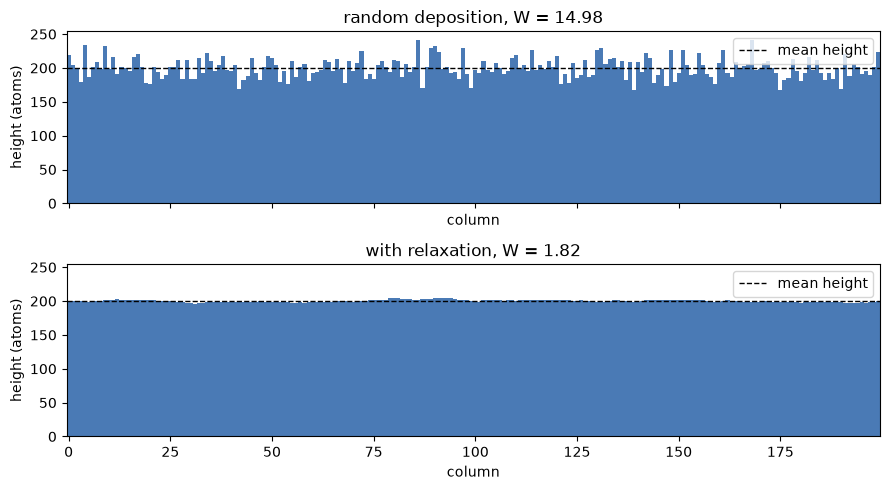

In [7]:
rng = np.random.default_rng(0)
cols, coin_flips = rng.integers(200, size=200 * 200), rng.random(200 * 200)
h_rd = np.bincount(cols, minlength=200)
h_sr = np.zeros(200, np.int64)
sr.relax_deposit_numba(h_sr, cols, coin_flips)
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True, sharey=True)
plot_surface(h_rd, ax=axes[0], title=f"random deposition, W = {roughness(h_rd):.2f}")
plot_surface(h_sr, ax=axes[1], title=f"with relaxation, W = {roughness(h_sr):.2f}")
fig.tight_layout(); plt.show()

**What to notice:** same atoms, same landing sites, but the relaxed film is far smoother (compare the `W` values in
the titles). Its bumps are also *wider*: neighbouring columns are now **correlated** (similar to each other),
because each atom's fate depends on its neighbours.

## 6. Scaling up: four substrate sizes

`RelaxSettings` holds the Phase 2 defaults. `scripts/run_phase2.py` runs `run_ensemble` for `L = 25, 50, 100, 200`
columns, each for 20,000 ML and 20 runs. Thanks to Numba this full-size run takes about a second, so we do it here at
full size.

In [8]:
base = sr.RelaxSettings()
print(base)
SIZES = [25, 50, 100, 200]
t0 = time.perf_counter()
curves = {L: sr.run_ensemble(sr.RelaxSettings(n_columns=L)) for L in SIZES}
print(f"4 ensembles in {time.perf_counter() - t0:.1f} s")

RelaxSettings(n_columns=200, n_monolayers=20000, n_runs=20, n_points=45, seed=42)


4 ensembles in 1.2 s


Check against the saved table `results/phase2_surface_relaxation/data.csv` (it stacks the four sizes, with a
`n_columns` column):

In [9]:
saved = pd.read_csv(os.path.join(RESULTS, "phase2_surface_relaxation", "data.csv"))
for L in SIZES:
    diff = np.abs(curves[L]["roughness_mean"].values - saved[saved["n_columns"] == L]["roughness_mean"].values).max()
    print(f"L = {L:3d}: max |difference| vs saved = {diff:.1e}")

L =  25: max |difference| vs saved = 2.2e-16
L =  50: max |difference| vs saved = 2.2e-16
L = 100: max |difference| vs saved = 2.2e-16
L = 200: max |difference| vs saved = 2.2e-16


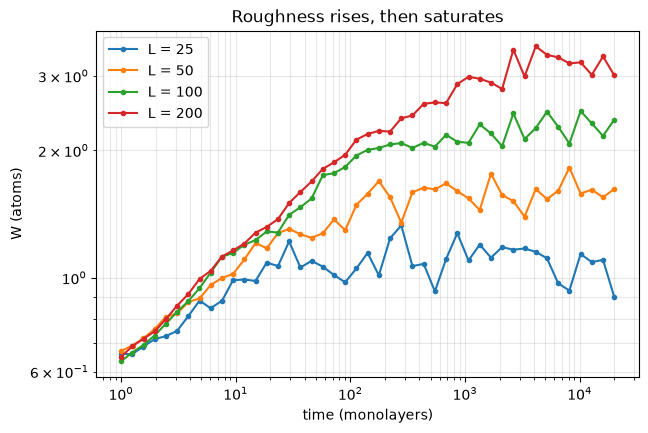

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for L, df in curves.items():
    ax.loglog(df["monolayers"], df["roughness_mean"], "o-", ms=3, label=f"L = {L}")
ax.set(xlabel="time (monolayers)", ylabel="W (atoms)", title="Roughness rises, then saturates")
ax.legend(); ax.grid(True, which="both", alpha=0.3); plt.show()

**What to notice:** all four curves start together and rise along the same line, then each one bends over and goes
flat. Wider substrates go flat **later** and at a **higher** level.

## 7. Measuring: beta, saturation, alpha and the data collapse

### 7a. Growth exponent beta (the early rise)

`beta` must be fitted *before* saturation bends the curve. `scripts/run_phase2.py` uses `L = 200` and only times up
to 100 ML (`EARLY_ML = 100`).

surface relaxation: beta = 0.248 +/- 0.003   (Edwards-Wilkinson theory: 0.25)


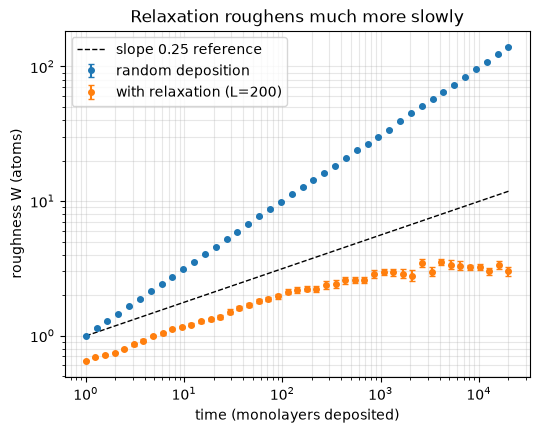

In [11]:
early = curves[200][curves[200]["monolayers"] <= 100]
beta, beta_err = fit_growth_exponent(early["monolayers"], early["roughness_mean"])
rd_curve = rd.run_ensemble(rd.RDSettings(n_monolayers=20000, n_runs=20))
print(f"surface relaxation: beta = {beta:.3f} +/- {beta_err:.3f}   (Edwards-Wilkinson theory: 0.25)")
ax = plot_roughness_loglog({"random deposition": rd_curve, "with relaxation (L=200)": curves[200]}, reference_slope=0.25)
ax.set_title("Relaxation roughens much more slowly"); plt.show()

**What to notice:** the relaxed film's early slope is about a quarter (saved value: beta = 0.248 ± 0.003 in
`results/phase2_surface_relaxation/settings.json`), half the random-deposition slope. "4 times longer gives 2 times
rougher" becomes "16 times longer gives 2 times rougher".

### 7b. Saturation width and the exponent alpha

`sr.saturation_width(df)` averages `W` over the last 20% of the measurement points, where the curve is flat. Theory
says `W_sat ~ L^alpha` with `alpha = 1/2`. Fitting a power law of `W_sat` against `L` uses exactly the same
`fit_growth_exponent` function: it fits any `y = A x^slope` on log-log axes.

In [12]:
w_sat = {L: sr.saturation_width(df) for L, df in curves.items()}
for L, w in w_sat.items():
    print(f"L = {L:3d}: W_sat = {w:.3f}")
alpha, alpha_err = fit_growth_exponent(np.array(SIZES), np.array([w_sat[L] for L in SIZES]))
print(f"alpha = {alpha:.3f} +/- {alpha_err:.3f}   (theory 0.5)")
print("saved summary:", {k: v for k, v in json.load(open(os.path.join(RESULTS, "phase2_surface_relaxation", "settings.json")))["summary"].items()
                         if k in ("beta", "alpha", "w_sat")})

L =  25: W_sat = 1.063
L =  50: W_sat = 1.593
L = 100: W_sat = 2.279
L = 200: W_sat = 3.220
alpha = 0.532 +/- 0.014   (theory 0.5)
saved summary: {'beta': 0.24825169142990222, 'w_sat': {'25': 1.0625260897367061, '50': 1.5926222367706613, '100': 2.2792873281335457, '200': 3.2199567816077135}, 'alpha': 0.5315807872682393}


**What to notice:** doubling the width multiplies the plateau by about 1.4 (= sqrt 2): saved plateaus 1.06, 1.59,
2.28, 3.22 for `L` = 25, 50, 100, 200, and `alpha = 0.53 ± 0.01`, close to 1/2.

### 7c. How long until saturation? (crossover time ~ L^2)

A rough, transparent estimate: the first measured time at which `W` reaches 90% of its plateau. This is a quick
check written for this notebook (not a project function), so expect it to be approximate.

In [13]:
t_cross = {}
for L, df in curves.items():
    reached = df[df["roughness_mean"] >= 0.9 * w_sat[L]]
    t_cross[L] = reached["monolayers"].iloc[0]
    print(f"L = {L:3d}: W reaches 90% of plateau at about {t_cross[L]:8.0f} ML")
z, z_err = fit_growth_exponent(np.array(SIZES), np.array([t_cross[L] for L in SIZES]))
print(f"crossover time ~ L^{z:.2f}   (theory: L^2)")

L =  25: W reaches 90% of plateau at about        9 ML
L =  50: W reaches 90% of plateau at about      113 ML
L = 100: W reaches 90% of plateau at about      222 ML
L = 200: W reaches 90% of plateau at about     1072 ML
crossover time ~ L^2.14   (theory: L^2)


**What to notice:** this crude estimate gives about 9, 113, 222 and 1072 ML for `L` = 25, 50, 100, 200 and an
exponent of 2.14, close to the theoretical 2. The individual times are noisy (the curve approaches its plateau
slowly and the plateau itself fluctuates), so treat this as a sanity check rather than a measurement. Compare with
the POR note in `src/thin_film/ideal.py` ("100 columns saturate after about 1000 ML", hence a 3000 ML run): by this
90% criterion `L = 100` gets there sooner (about 222 ML), so 3000 ML is comfortably long enough to show the plateau.

### 7d. Data collapse

If `W` rises like `t^(1/4)` until a time `~ L^2` and then sits at `~ L^(1/2)`, then plotting `W / L^0.5` against
`t / L^2` should put all four curves on **one** curve. This is the Family-Vicsek scaling form; seeing the curves
collapse is strong evidence that `alpha = 1/2` and `z = 2` (`z` is the exponent of the crossover time).

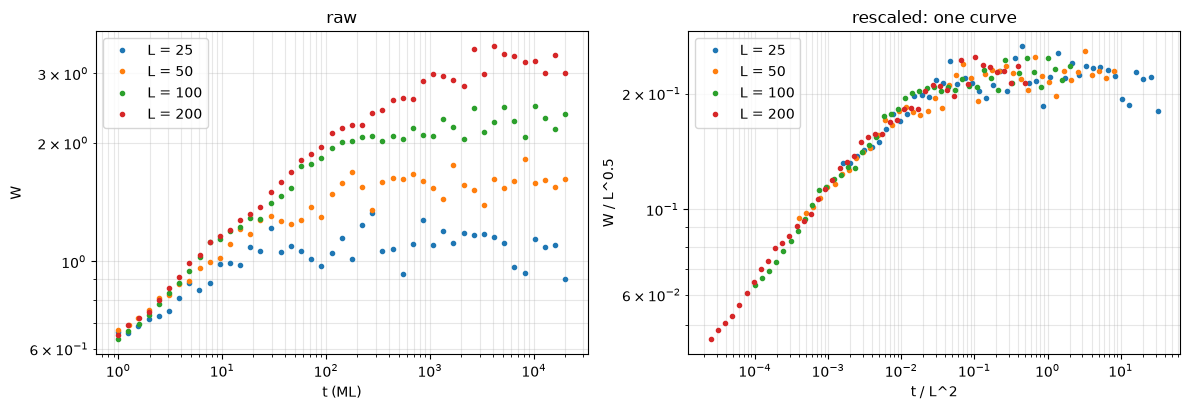

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for L, df in curves.items():
    axes[0].loglog(df["monolayers"], df["roughness_mean"], "o", ms=3, label=f"L = {L}")
    axes[1].loglog(df["monolayers"] / L**2, df["roughness_mean"] / L**0.5, "o", ms=3, label=f"L = {L}")
axes[0].set(xlabel="t (ML)", ylabel="W", title="raw")
axes[1].set(xlabel="t / L^2", ylabel="W / L^0.5", title="rescaled: one curve")
for ax in axes: ax.legend(); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout(); plt.show()

**What to notice:** on the right, the four separate curves fall on top of each other. That is what the README calls
"data collapse with z = 2".

## 8. Performance: why a loop is needed and what Numba does

### 8a. Why Phase 1's shortcut does not work here

In notebook 1, `np.bincount` counted all atoms at once because the **order** of arrival did not matter. With
relaxation, where an atom ends up depends on the surface it finds, which depends on all earlier atoms. Demonstration:
shuffle the arrival order of the same atoms.

In [15]:
rng = np.random.default_rng(11)
cols, coin_flips = rng.integers(50, size=5000), rng.random(5000)
order = np.random.default_rng(12).permutation(5000)

print("random deposition, original vs shuffled order identical:",
      np.array_equal(np.bincount(cols, minlength=50), np.bincount(cols[order], minlength=50)))
a, b = np.zeros(50, np.int64), np.zeros(50, np.int64)
sr.relax_deposit_numba(a, cols, coin_flips)
sr.relax_deposit_numba(b, cols[order], coin_flips[order])
print("relaxation,        original vs shuffled order identical:", np.array_equal(a, b))

random deposition, original vs shuffled order identical: True
relaxation,        original vs shuffled order identical: False


So relaxation needs a loop that processes atoms one at a time, in order. A Python `for` loop over millions of atoms is
slow, because Python interprets every line afresh on each pass and every number is a full Python object.

### 8b. What JIT compilation is

**Numba** is a library that translates a Python function into machine code (the CPU's native instructions) the
first time it is called. This is **just-in-time (JIT) compilation**. The compiled version knows the exact types
(64-bit integers, floats) and skips the interpreter, so loops run at speeds close to C.

In `surface_relaxation.py` it is one line:

```python
relax_deposit_numba = njit(cache=True)(relax_deposit_python)
```

`njit` = "no-Python mode JIT" (the whole function must be compilable). `cache=True` stores the machine code on disk,
so later sessions skip the compile step. To *see* the compile cost, we compile a fresh copy without the cache:

In [16]:
fresh = njit(sr.relax_deposit_python)          # new, not-yet-compiled copy
h = np.zeros(200, np.int64)
t0 = time.perf_counter(); fresh(h, cols[:10], coin_flips[:10]); first = time.perf_counter() - t0
t0 = time.perf_counter(); fresh(h, cols[:10], coin_flips[:10]); second = time.perf_counter() - t0
print(f"first call (compile + run): {first * 1e3:8.1f} ms")
print(f"second call (run only)    : {second * 1e3:8.4f} ms")

first call (compile + run):     58.4 ms
second call (run only)    :   0.0294 ms


### 8c. Timing comparison and the identical-output check

The same experiment as `timing_experiment()` in `scripts/run_phase2.py`: 200,000 atoms on 200 columns, both versions,
best of 3 runs, compile time excluded. Then the most important check: **both versions must build exactly the same
film**, because they get exactly the same random numbers (`tests/test_surface_relaxation.py::test_numba_matches_python_exactly`).

In [17]:
rng = np.random.default_rng(0)
n_atoms = 200_000
cols, coin_flips = rng.integers(200, size=n_atoms), rng.random(n_atoms)
sr.relax_deposit_numba(np.zeros(200, np.int64), cols[:10], coin_flips[:10])   # make sure it is compiled

def best_time(kernel, repeats=3):
    best = np.inf
    for _ in range(repeats):
        h = np.zeros(200, np.int64)
        t0 = time.perf_counter(); kernel(h, cols, coin_flips); best = min(best, time.perf_counter() - t0)
    return best, h

rows = []
for name, kernel in [("python", sr.relax_deposit_python), ("numba", sr.relax_deposit_numba)]:
    secs, film_out = best_time(kernel)
    rows.append({"implementation": name, "seconds": secs, "atoms_per_second": n_atoms / secs, "film": film_out})
timing = pd.DataFrame(rows)
print(timing[["implementation", "seconds", "atoms_per_second"]].to_string(index=False))
print(f"speed-up on this machine, this run: {timing.seconds[0] / timing.seconds[1]:.0f}x")
print("identical films:", np.array_equal(rows[0]["film"], rows[1]["film"]), "| atoms conserved:", rows[1]["film"].sum() == n_atoms)

implementation  seconds  atoms_per_second
        python 0.070375      2.841901e+06
         numba 0.000588      3.398950e+08
speed-up on this machine, this run: 120x
identical films: True | atoms conserved: True


In [18]:
saved_timing = pd.read_csv(os.path.join(RESULTS, "phase2_numba_timing", "data.csv"))
print("saved in results/phase2_numba_timing (when scripts/run_phase2.py was last run):")
print(saved_timing.to_string(index=False))
print("saved speed-up:", round(json.load(open(os.path.join(RESULTS, "phase2_numba_timing", "settings.json")))["summary"]["speedup"], 1))

saved in results/phase2_numba_timing (when scripts/run_phase2.py was last run):
implementation  atoms  seconds  atoms_per_second
        python 200000 0.068763      2.908557e+06
         numba 200000 0.000538      3.717472e+08
saved speed-up: 127.8


**What to notice:** timings vary from run to run and machine to machine, so your live numbers will differ a little
from the saved ones (saved: about 2.9 million atoms/s in plain Python vs 3.7e8 with Numba, a 128x speed-up). The
identical-film check, however, must always say `True`: speed without correctness is worthless.

`sr.deposit(heights, n_atoms, rng)` is the convenience wrapper the rest of the code uses: it draws random numbers in
chunks of one million (to limit memory) and calls the Numba kernel.

## 9. How the `results/phase2_*` folders are produced

`PYTHONPATH=src .venv/bin/python scripts/run_phase2.py` runs two functions (we did not run the script; we repeated its
steps above):

* `scaling_experiment()`: the four-size ensembles (Part 6), `beta` on `L = 200` up to 100 ML (7a), `W_sat` and
  `alpha` (7b), a random-deposition comparison curve, a three-panel figure (comparison, saturation, data collapse),
  saved with `save_result` to **`results/phase2_surface_relaxation/`**.
* `timing_experiment()`: the Python-vs-Numba timing (8c), saved to **`results/phase2_numba_timing/`**.

The tests in `tests/test_surface_relaxation.py` check the hand-made cases (Part 4), Numba = Python exactly (8c),
`beta ≈ 0.25` within 0.05, and that `W` saturates with `alpha ≈ 0.5` within 0.1.

## 10. Recap and exercises

### What we learned
* "Roll into a lower neighbour" is a purely local rule, yet it changes the global behaviour: `beta` drops from 1/2 to
  about 1/4, and the roughness saturates at a plateau that grows like `L^(1/2)` after a time that grows like `L^2`.
* Rescaling by those exponents collapses all sizes onto one curve.
* Because each atom's fate depends on earlier atoms, the simulation needs an ordered loop; Numba compiles it to
  machine code and the output is bit-for-bit identical to plain Python.

### Step → module/function → script map

| Step | Module / function | Script / test |
|---|---|---|
| relaxation rule | `surface_relaxation.relax_deposit_python` | `tests/test_surface_relaxation.py` |
| compiled rule | `surface_relaxation.relax_deposit_numba` (`njit(cache=True)`) | `scripts/run_phase2.py::timing_experiment` |
| many atoms, chunked | `surface_relaxation.deposit` | |
| one film's W(t), ensemble | `surface_relaxation.simulate`, `run_ensemble` | `scripts/run_phase2.py::scaling_experiment` |
| plateau | `surface_relaxation.saturation_width` | same |
| beta, alpha fits | `roughness.fit_growth_exponent` | same |
| saved results | `results.save_result` | `results/phase2_surface_relaxation/`, `results/phase2_numba_timing/` |

### Try changing X and see Y
1. Change the rule so an atom rolls only if the neighbour is lower by **2 or more** (copy `my_relax`). Does `W_sat`
   go up or down?
2. Fit `beta` for `L = 200` using times up to 1000 ML instead of 100. Why does the value drop?
3. Add `L = 400` to `SIZES`. Does the plateau land near `3.22 * sqrt(2)`? (It needs a longer run to saturate; try
   `n_monolayers=80000`.)
4. Time `relax_deposit_python` vs `relax_deposit_numba` for 10,000 atoms instead of 200,000. Does the ratio change?
5. Remove the periodic boundary in `my_relax` (treat a missing neighbour as "not lower"). What happens near the edges?

**Next:** notebook 3 replaces the always-on rolling rule with hops whose odds depend on temperature and deposition rate.